# Full-text assessment: codebook logic, PDFs and paper info

In this step,  we read the full text of the included papers and answer the questions in the codebook (`documents/full-text_assessment_questions.xlsx`). To perform the question answering we build a Streamlit tool (we use our own tool because we want to be able to audit the codebook logic, pre-fill the paper info section, and be able to easily update labels on the go for different questions).   

This notebook: 

| # | Step | Output |
|---|---|---|
| 1 | Parses the codebook and **audit its branching logic** | issue table |
| 2 | Draws the branching logic as a **graph** | `codebook_graph.png`, `codebook_graph.md` (Mermaid) |
| 3 | Copies the PDFs out of Zotero's storage into the repo | `data/pdfs/<paper_id>.pdf`, `pdf_manifest.csv` |
| 4 | Builds the pre-filled *Paper info* section | `paper_info.csv` |

The xlsx is the single source of truth. Questions are keyed by their stable **fixID** (e.g. `MIS.def`). The parser, the audit and the graph all live in
[`src/full_text_assessment/`](../src/full_text_assessment/), and the tool uses the **same code**, so what
this notebook documents is exactly what the tool runs. The tool also re-runs the audit when it starts
and refuses to open while the codebook has errors.

Outputs (i.e., responses to the questionnaire) go to `../data/processed/full_text_assessment/`. 

## Setup

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd

from src.full_text_assessment.codebook import CODEBOOK_PATH, load_codebook
from src.full_text_assessment.audit import (
    ERROR, INFO, WARNING, audit, draw_dependency_graph, issues_frame, question_table, to_mermaid,
)
from src.full_text_assessment.store import DATA_DIR

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 100)
print(f"working directory: {Path.cwd()}")

working directory: /home/m-chaves/slr_climate_nlp


## Step 1: the codebook and its branching logic

Each xlsx row becomes one question. The columns the tool relies on are:

- **fixID**: the stable key of the question (`MIS.def`). Answers, conditions and label pools all
  refer to it, so adding, removing or reordering questions never re-points anything.
- **ID**: the display number (`MIS.3`). Shown next to the fixID in the tool, but never used as a key:
  it changes whenever rows move.
- **Level**: `paper`, or `dataset` for questions answered once per dataset. Only DA.2–DA.17 are
  dataset-level; the gate `DA.is_data` ("does the study use at least one dataset?") is paper-level.
- **Type**: single-select, multi-select, free text, integer, or YYYY. The `Updatable` prefix means
  new labels can be added while reading.
- **Labels**: one per line. `N = description` labels are *coded*: the code N is stored and compared.
  `same labels as ML.task` makes a question share ML.task's label pool, in both directions.
- **Condition**: when the question applies, written with **fixIDs**. Parsed by a small grammar
  (`=`, `!=`, `in (…)`, `not in (…)`, `AND`, `OR`); anything else is an error rather than a silent guess.

In [2]:
codebook = load_codebook()

overview = (pd.DataFrame([{"section": q.section, "level": q.level,
                           "conditional": q.condition is not None} for q in codebook.questions])
            .groupby(["section", "level"], sort=False)
            .agg(questions=("conditional", "size"), conditional=("conditional", "sum")))
print(f"{len(codebook.questions)} questions from {CODEBOOK_PATH.relative_to(PROJECT_ROOT)}")
overview

65 questions from documents/full-text_assessment_questions.xlsx


questions  \
section                                            level                
Climate                                            paper            2   
Misinformation                                     paper           12   
Polarization                                       paper            8   
Intersection (Misinfo. and Polar.)                 paper            4   
Motivations, methodology, actionability, alignment paper            9   
Stakeholders                                       paper            3   
Conclusions and findings                           paper            7   
Data                                               paper            1   
                                                   dataset         16   
ML and computational methods                       paper            3   

                                                            conditional  
section                                            level                 
Climate                                            paper              0  
Misinformation                                     paper             11  
Polarization                                       paper              7  
Intersection (Misinfo. and Polar.)                 paper              4  
Motivations, methodology, actionability, alignment paper              6  
Stakeholders                                       paper              2  
Conclusions and findings                           paper              2  
Data                                               paper              0  
                                                   dataset           16  
ML and computational methods                       paper              0

### How conditions are evaluated

- **Three outcomes.** Given the answers so far, each question is *shown*, *skipped* (stored as `NA`), or
  *pending* (a parent is still unanswered, so the tool waits rather than guessing).
- **Skipping propagates.** A comparison on a skipped parent is false, so a skipped question skips its
  children. This matters for `!=`: without it, `DA.size_unit` (`DA.size != 'not reported'`) would show
  when `DA.size` itself was skipped, because NA ≠ 'not reported'.
- **Multi-selects are sets.** `X in (…)` holds if *any* selected label is in the list. `X not in (…)` holds
  if *at least one* selected label is outside it. (In practice, "not reported" / "unclear" / "none" cannot
  be combined with other labels: the tool makes them exclusive.)
- **Free text** is compared through its label. A typed answer counts as "another value", so
  `MOT.motiv_cite != 'not reported'` holds for any cited motivation.
- Comparisons are case-insensitive.

### Audit

The checks:
- **fixIDs** exist for every row, are **unique, also ignoring case** (`MIS.def` and `MIS.Def` would be
  an error), match `SECTION.name`, and start with their section key;
- every condition parses and names existing **fixIDs**; a condition or label pool that still uses a
  display ID is an error that names the fixID to use instead;
- every value a condition mentions is a label of that question;
- no cycles, and parents come first in the xlsx;
- no paper-level question depends on a dataset-level one;
- labels are unique, with no leftover `*` and no `|` (the multi-select separator);
- coded labels are consistent;
- each question has an escape label (`not reported`, `unclear`, `none`, …) or a condition that
  guarantees an answer exists.

**Errors** block the tool, **warnings** are probable mistakes, and **info** notes need no action.

In [3]:
issues = audit(codebook)
counts = {s: sum(i.severity == s for i in issues) for s in (ERROR, WARNING, INFO)}
print(counts)
issues_frame(issues)

{'error': 0, 'warning': 0, 'info': 13}


,severity,qid,check,message
0,info,MIS.def,escape label,no 'not reported'/'unclear'-type label; relies on its condition (MIS.has_def='yes') to guarantee an answer...
1,info,MIS.agent_identification,condition,"mentions 'NA', which is no label of MIS.agents; harmless, because a skipped parent already skips its children"
2,info,MIS.metrics_desc,condition,"mentions 'NA', which is no label of MIS.metrics; harmless, because a skipped parent already skips its chil..."
3,info,POL.def,escape label,no 'not reported'/'unclear'-type label; relies on its condition (POL.has_def='yes') to guarantee an answer...
4,info,MP.rel_evidence,condition,"mentions 'NA', which is no label of MP.rel_claimed; harmless, because a skipped parent already skips its c..."
5,info,MP.rel_cite,condition,"mentions 'NA', which is no label of MP.rel_claimed; harmless, because a skipped parent already skips its c..."
6,info,MOT.motiv_clear_cite,escape label,no 'not reported'/'unclear'-type label; relies on its condition (MOT.motiv_clear='yes') to guarantee an an...
7,info,MOT.theory_why,escape label,no 'not reported'/'unclear'-type label; relies on its condition (MOT.theory!=0) to guarantee an answer exists
8,info,MOT.validation,escape label,no 'not reported'/'unclear'-type label; relies on its condition (MOT.theory=4) to guarantee an answer exists
9,info,MOT.action_why,escape label,no 'not reported'/'unclear'-type label; relies on its condition (MOT.action!=0) to guarantee an answer exists


The audit is clean: no errors and no warnings. The info notes are of two kinds:

- `MIS.agent_identification`, `MIS.metrics_desc`, `MP.rel_evidence` and `MP.rel_cite` list `'NA'` in
  their conditions, although `NA` is no label of the parent. This is kept deliberately and is harmless,
  because skipping already propagates.
- Some free-text or multi-select questions have no escape label. Each of them is conditional on a parent
  answer that guarantees there is something to cite (e.g. `MIS.def` only appears when `MIS.has_def` = yes).

### Every question at a glance

In [4]:
question_table(codebook)

,fixID,ID,level,type,condition,parents,children,label pool,n labels,escape labels
0,CLI.domain,CLI.1,paper,Updatable multi-select,,,,,2,"unclear, not reported"
1,CLI.focus,CLI.2,paper,Single-select,,,,,3,unclear
2,MIS.is_present,MIS.1,paper,Single-select,,,"MIS.has_def, MIS.type, MIS.agents, MIS.metrics, MIS.truth_status, MIS.responses, MIS.findings, MP.rel_meas...",,3,
3,MIS.has_def,MIS.2,paper,Single-select,"MIS.is_present in ('yes, direct', 'yes, indirect')",MIS.is_present,"MIS.def, MIS.def_src",,2,
4,MIS.def,MIS.3,paper,Free text,MIS.has_def='yes',MIS.has_def,,,0,
5,MIS.def_src,MIS.4,paper,Free text,MIS.has_def='yes',MIS.has_def,,,2,"not reported, unclear"
6,MIS.type,MIS.5,paper,Updatable multi-select,"MIS.is_present in ('yes, direct', 'yes, indirect')",MIS.is_present,,,2,"not reported, unclear"
7,MIS.agents,MIS.6,paper,Updatable multi-select,"MIS.is_present in ('yes, direct', 'yes, indirect')",MIS.is_present,MIS.agent_identification,,2,"not reported, unclear"
8,MIS.agent_identification,MIS.7,paper,Free text,"MIS.agents not in ('NA', 'not reported', 'unclear')",MIS.agents,,,2,"unclear, not reported"
9,MIS.metrics,MIS.8,paper,Updatable multi-select,"MIS.is_present in ('yes, direct', 'yes, indirect')",MIS.is_present,MIS.metrics_desc,,2,"not reported, unclear"


### Codebook version

Every codebook gets a **version**: a hash over what reviewers see and what the logic uses (per
question: display ID, text, type, level, xlsx labels, condition, label pool). Labels added while reading
are not part of it. Each version is recorded in `codebook_versions.json`, so later edits can be diffed
against the version a paper was answered under (see *Changing the codebook* below).

In [5]:
from src.full_text_assessment import store

version = store.record_version(codebook)
print(f"current codebook version: {version}")
print(f"versions on record: {len(store.load_versions())}")

current codebook version: bbc89907ae72
versions on record: 1


## Step 2: the logic as a graph

- There is one column per section.
- Within a column, questions go down in xlsx order and step right with their depth in the branching.
  Each node shows its fixID in bold, and its display ID before the question text.
- Each parent drops one spine, and the trigger is printed once above the first child it opens.
- Conditions that cross sections are dashed, and are spelled out under the child. Examples:
  `MP.rel_measured` needs both `MIS.is_present` and `POL.is_present`; `CON.motiv_match` needs
  `MOT.motiv_cite` and `CON.concl`; every dataset question hangs off `DA.is_data`.
- Colour and shape both mark the level: blue circles are paper-level, orange squares are dataset-level.

The same graph is exported as Mermaid (`codebook_graph.md`), which renders on GitHub.

51 dependency edges -> data/processed/full_text_assessment/codebook_graph.md


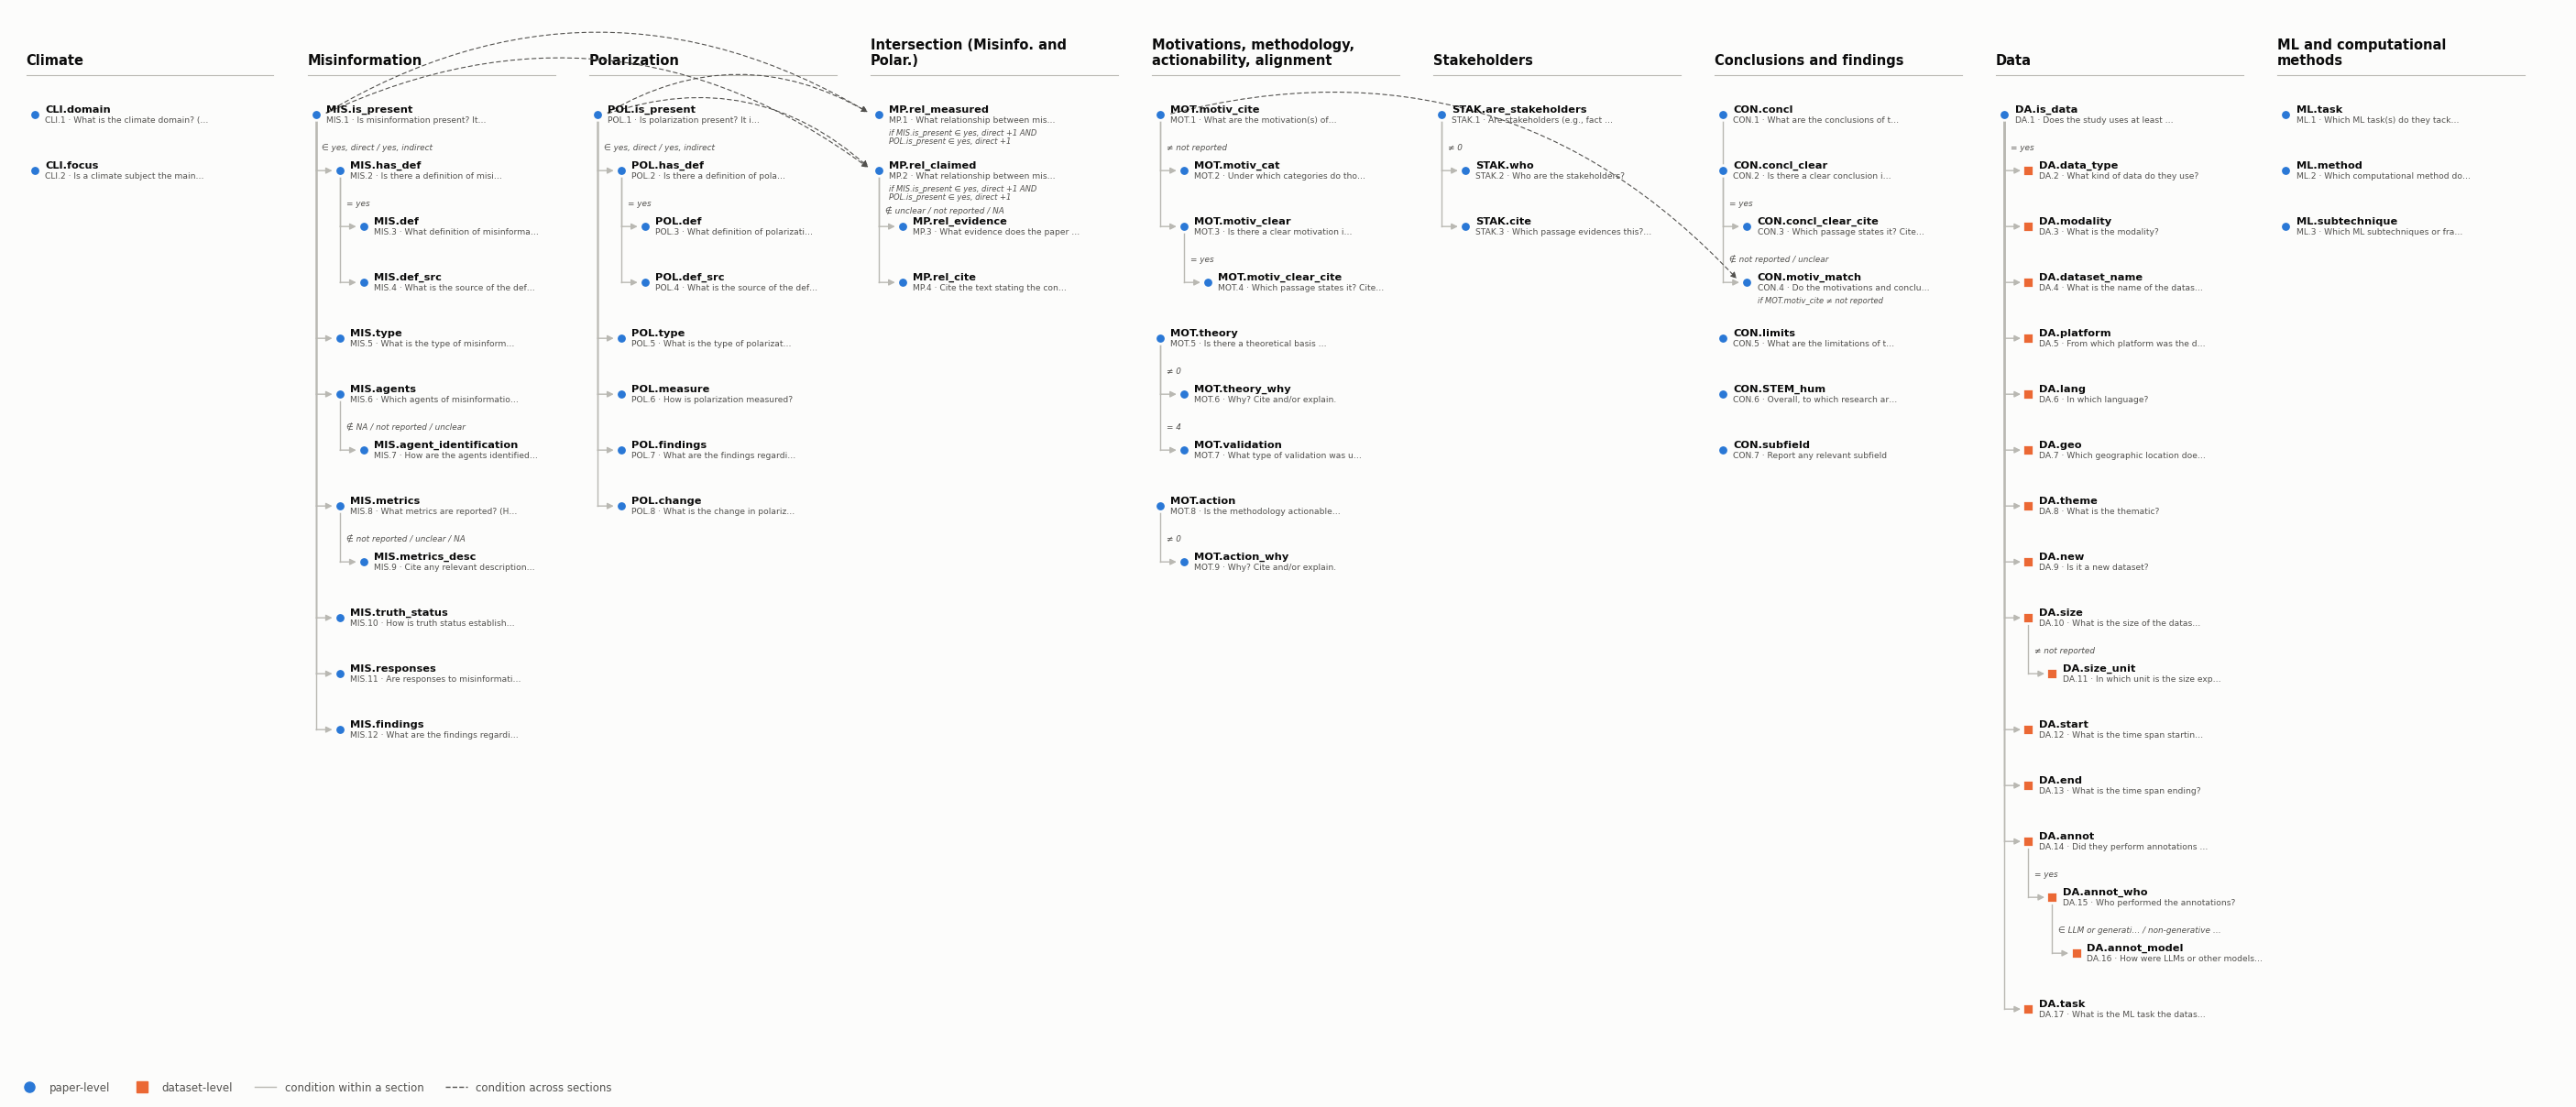

In [6]:
fig = draw_dependency_graph(codebook)
DATA_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(DATA_DIR / "codebook_graph.png", dpi=150, bbox_inches="tight")

mermaid = to_mermaid(codebook)
(DATA_DIR / "codebook_graph.md").write_text(
    "# Full-text assessment: branching logic\n\n"
    "Generated by `notebooks/06_full_text_assessment_codebook.ipynb` from the codebook xlsx. "
    "Single boxes are paper-level, double boxes dataset-level.\n\n"
    f"```mermaid\n{mermaid}\n```\n", encoding="utf-8")
print(f"{mermaid.count('-->')} dependency edges -> {(DATA_DIR / 'codebook_graph.md').relative_to(PROJECT_ROOT)}")

## Step 3: copy the PDFs into the repo

Zotero keeps each attachment at `<storage>/<attachment key>/<filename>`. The storage directory comes
from `ZOTERO_STORAGE` in `.env`. The attachment keys come from the Zotero API (read-only key), via the
`ZoteroLibrary` client from notebook 05's module. When a paper has several PDFs attached, the most
recently added one is used, since the usual reason for a second PDF is a swapped-in published version.

Copies go to `data/pdfs/<paper_id>.pdf`, which is **gitignored** (copyright, size). Re-running is safe:
unchanged files are skipped.

In [7]:
from src.full_text_assessment.pdfs import build_manifest, copy_pdfs, storage_dir

manifest = copy_pdfs(build_manifest(storage_dir()))
print(manifest["copy_status"].value_counts().to_string())
manifest[manifest["n_pdfs"] != 1][["paper_id", "n_pdfs", "filename"]]

copy_status
up to date    81


,paper_id,n_pdfs,filename
42,2667541209eb2eb7,2,TeamX at CheckThat! 2023 Multilingual and Multimodal Approach for Check-Worthiness Detection.pdf


## Step 4: the pre-filled *Paper info* section

The tool shows these details read-only above the questions: title, year, venue, paper type, every
identifier, the research area assigned at screening, and the PDF path. The answer files carry only
`paper_id` and join to this file.

In [8]:
from src.full_text_assessment.prefill import PAPER_INFO_PATH, write_paper_info

info = write_paper_info()
print(f"{len(info)} papers -> {PAPER_INFO_PATH.relative_to(PROJECT_ROOT)}")
print(f"with a PDF on disk: {(info['pdf_path'] != '').sum()}")
print(info["research_area"].value_counts().to_string())
info.head(3)

81 papers -> data/processed/full_text_assessment/paper_info.csv
with a PDF on disk: 81
research_area
Misinformation    33
Polarization      30
Both              18


,paper_id,title,year,published_in,paper_type,doi,arxiv_id,acl_id,scopus_eid,wos_id,research_area,pdf_path
0,7ce41199140428b1,Social determinants of content selection in the age of (mis)information,2014,scopus: Lecture Notes in Computer Science Including Subseries Lecture Notes in Artificial Intelligence and...,scopus: Conference Paper,10.1007/978-3-319-13734-6_18,,,2-s2.0-84914141540,,Both,data/pdfs/7ce41199140428b1.pdf
1,5f473c034602c53f,"Fake news and indifference to scientific fact: President Trump’s confused tweets on global warming, climat...",2018,"scopus: Scientometrics, wos: SCIENTOMETRICS, semantic_scholar: Scientometrics","scopus: Letter, wos: Article, semantic_scholar: JournalArticle",10.1007/s11192-018-2847-y,,,2-s2.0-85049878087,WOS:000442737700035,Misinformation,data/pdfs/5f473c034602c53f.pdf
2,3bde570e4a60cf42,Measuring online political dialogue: Does polarization trigger more deliberation?,2020,"scopus: Media and Communication, wos: MEDIA AND COMMUNICATION","scopus: Article, wos: Article",10.17645/mac.v8i4.3149,,,2-s2.0-85098069682,WOS:000580624700005,Polarization,data/pdfs/3bde570e4a60cf42.pdf


## Running the tool

```bash
streamlit run src/full_text_assessment/app.py
```

It opens on http://localhost:8501/

- **Reviewer.** Pick your name in the sidebar, or choose *new reviewer* and enter your **full name**.
  Names are matched ignoring case and extra spaces, so "ada lovelace" is the same reviewer as
  "Ada Lovelace". The choice is remembered on this machine.
- **Sidebar.** Progress, filters, the paper list, prev / next / next-unfinished, a side-by-side PDF
  toggle, and label renaming.
- **Main area.** Paper info, the timer, an *Open PDF* button, a *Mark complete* button (enabled once
  nothing is left), then one tab per section, so you can move freely.
- **Data tab.** `DA.is_data` first. If the paper uses datasets, a selector lets you add, name, delete,
  and switch between datasets, so they can be filled in alternately.

### When answers are saved

**Immediately, on every change**: each answer, each dataset edit, and the notes. There is no save
button, and a paper left *in progress* is fully on disk. *Mark complete* only sets `status`.

### Labels

Typing into an updatable question's box adds a label to the shared codebook, for every paper and
reviewer. Picking *other (free text)* on a free-text question never adds a label.

**Renames rewrite the files.** *Rename a label* logs the rename in `labels_added.csv`, then replaces the
old name in every stored answer of `papers.csv` and `datasets.csv`: for every reviewer, and for both
questions of a shared pool (`ML.task` and `DA.task`). Typed free-text answers are never touched. Every
save also resolves names again, so a tab still holding the old name cannot write it back. **The CSVs
therefore always hold the current label names.** With separate git clones, do renames when the others
have pushed: a rename touches many rows.

- **The new name must not already exist** in the question's labels (ignoring case). A rename never merges
  two labels.
- **Undoing is a rename back.** Renaming A → B and then B → A leaves A as the single label.
- **Typing an old name** of a renamed label saves the current name, and the tool says so
  ("“A” was renamed to “B”; saved as “B”"). Old names are never logged as new labels.

### Reload from disk

The sidebar button re-reads the answers (`papers.csv`, `datasets.csv`), the codebook xlsx, the label log
and the paper info from the files, and rebuilds the form from them. Use it after pulling another
reviewer's work or editing a file outside the tool. Nothing is lost, since every change is already saved.
The only thing it forgets is the in-session memory that restores answers hidden by the branching when a
change is undone. Your reviewer, paper, filters and timer are kept.

### Time per paper

The timer in the paper header counts, per reviewer and paper, the time the paper is **open in the
tool**. It updates every 30 s.
- It **stops after 15 minutes without any interaction**, so a tab left open overnight adds nothing.
- **⏸ Pause** stops it by hand. **Any interaction resumes it**, so a forgotten pause loses nothing.
- A gap of more than 90 s between ticks (a laptop asleep) counts as 90 s at most.
- Two open tabs of the same reviewer don't double-count.

Totals are in `time_log.csv`, one row per reviewer and paper. `store.time_per_paper()` gives a paper ×
reviewer table in minutes.

### Changing the codebook

Edit the xlsx freely, keeping each question's **fixID** unchanged when you reword it. The tool re-reads
it on the next interaction, and then:
- **Papers answered under an older version** show ⚠️ *needs review* in the paper list. When opened, a
  banner lists the questions that are 🆕 new, ✏️ changed (wording, labels, type, condition, level) or
  🗑 removed, and the affected questions carry a badge in their tab.
- **Nothing is lost.** Answers to removed questions stay in the CSV (their columns are kept) and are
  shown read-only under *Retired questions*. The first time a row is written under a new version, its
  previous state is copied to `papers_archive.csv` / `datasets_archive.csv`. This matters when a changed
  condition turns an answer into `NA`.
- **Completion needs a review.** The paper can't be complete again until any new questions are
  answered and the reviewer clicks *I've reviewed the codebook changes*.

### Files (`data/processed/full_text_assessment/`)

| File | Row = | Notes |
|---|---|---|
| `papers.csv` | paper × reviewer | one column per paper-level fixID, plus `status`, `codebook_version` (last confirmed), `saved_with`, `last_modified`, `notes` |
| `datasets.csv` | paper × reviewer × dataset | one column per dataset-level fixID, plus `dataset_idx`, `dataset_label`, `saved_with` |
| `labels_added.csv` | label event | append-only log of added and renamed labels (`pool`, `label`, `added_by`, `renamed_to`, …) |
| `time_log.csv` | reviewer × paper | `seconds`, `first_opened`, `last_seen` |
| `codebook_versions.json` | codebook version | every version seen, as fixID → fingerprint |
| `papers_archive.csv`, `datasets_archive.csv` | archived row | a row as it was before its first save under a newer codebook, with `archived_at` |

Conventions:
- `NA` means skipped by the branching logic.
- Multi-selects are joined with ` | `.
- `<fixID>__free = True` marks a typed free-text answer where the question also offers labels.
- Read with `pd.read_csv(path, dtype=str, keep_default_na=False)` so `NA` stays a string.
- Tests: `python -m pytest tests/`.